# Laboratorijska vježba 1 - Linearno programiranje
## Jure Rajčić

---

## Tekst zadatka

U restoranu **Gazda Klopić** moguće je imati stolove za 4, 6 i 8 ljudi. Stol za četvero stoji 800 kn, stol za šestero 900 kn, a stol za osmero košta 1000 kn. Očekuje se odjednom najmanje 240 gostiju. U stolove se namjerava investirati najviše 45000 kn. Očekuje se da odjednom mora biti barem 20 stolova za četiri osobe. Koliko kojih stolova nabaviti da bi restoran mogao odjednom primiti što je moguće više gostiju?

## 1. Matematički model polaznog problema

### Varijable odlučivanja:
- $x_1$ - broj stolova za 4 osobe
- $x_2$ - broj stolova za 6 osoba
- $x_3$ - broj stolova za 8 osoba

### Funkcija cilja:
Maksimizirati broj gostiju:
$$\max Z = 4x_1 + 6x_2 + 8x_3$$

### Ograničenja:
1. Budžetsko ograničenje (cijena stolova): $800x_1 + 900x_2 + 1000x_3 \leq 45000$
2. Minimalni broj gostiju: $4x_1 + 6x_2 + 8x_3 \geq 240$
3. Minimalni broj stolova za 4 osobe: $x_1 \geq 20$
4. Nenegativnost: $x_1, x_2, x_3 \geq 0$

### Standardni oblik:
$$\max Z = 4x_1 + 6x_2 + 8x_3$$

Uz ograničenja:
- $800x_1 + 900x_2 + 1000x_3 \leq 45000$
- $4x_1 + 6x_2 + 8x_3 \geq 240$
- $x_1 \geq 20$
- $x_1, x_2, x_3 \geq 0$

## 2. Dualni problem

### Dualne varijable:
- $y_1$ - dualna varijabla za budžetsko ograničenje (sjena cijena budžeta)
- $y_2$ - dualna varijabla za ograničenje minimalnog broja gostiju
- $y_3$ - dualna varijabla za minimalni broj stolova za 4 osobe

### Transformacija ograničenja:
Ograničenje $4x_1 + 6x_2 + 8x_3 \geq 240$ transformiramo u $-4x_1 - 6x_2 - 8x_3 \leq -240$

Ograničenje $x_1 \geq 20$ transformiramo u $-x_1 \leq -20$

### Dualni problem:
$$\min W = 45000y_1 - 240y_2 - 20y_3$$

Uz ograničenja:
- $800y_1 - 4y_2 - y_3 \geq 4$ (za $x_1$)
- $900y_1 - 6y_2 \geq 6$ (za $x_2$)
- $1000y_1 - 8y_2 \geq 8$ (za $x_3$)
- $y_1, y_2, y_3 \geq 0$

## 3. Rješavanje polaznog problema pomoću PuLP-a

In [134]:
# Instalacija potrebnih paketa (ako nisu instalirani)
# !pip install pulp matplotlib numpy

In [135]:
import pulp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Kreiranje problema (maksimizacija)
prob_primal = pulp.LpProblem("Restoran_Gazda_Klopić", pulp.LpMaximize)

# Varijable odlučivanja (kontinuirane)
x1 = pulp.LpVariable("x1_stolovi_4", lowBound=0, cat='Continuous')
x2 = pulp.LpVariable("x2_stolovi_6", lowBound=0, cat='Continuous')
x3 = pulp.LpVariable("x3_stolovi_8", lowBound=0, cat='Continuous')

# Funkcija cilja: maksimizirati broj gostiju
prob_primal += 4*x1 + 6*x2 + 8*x3, "Broj_gostiju"

# Ograničenja
prob_primal += 800*x1 + 900*x2 + 1000*x3 <= 45000, "Budžet"
prob_primal += 4*x1 + 6*x2 + 8*x3 >= 240, "Minimalni_broj_gostiju"
prob_primal += x1 >= 20, "Minimalni_stolovi_4"

# Rješavanje
prob_primal.solve()

# Ispis rezultata
print("="*60)
print("POLAZNI PROBLEM (KONTINUIRANE VARIJABLE)")
print("="*60)
print(f"Status: {pulp.LpStatus[prob_primal.status]}")
print(f"\nOptimalna vrijednost funkcije cilja: {pulp.value(prob_primal.objective):.2f} gostiju")
print(f"\nOptimalne vrijednosti varijabli:")
print(f"  x1 (stolovi za 4): {x1.varValue:.4f}")
print(f"  x2 (stolovi za 6): {x2.varValue:.4f}")
print(f"  x3 (stolovi za 8): {x3.varValue:.4f}")

# Provjera ograničenja
print(f"\nProvjera ograničenja:")
budzet_iskoristen = 800*x1.varValue + 900*x2.varValue + 1000*x3.varValue
print(f"  Budžet iskorišten: {budzet_iskoristen:.2f} / 45000 kn")
print(f"  Budžet iskorišten: {(budzet_iskoristen/45000)*100:.2f}%")

broj_gostiju = 4*x1.varValue + 6*x2.varValue + 8*x3.varValue
print(f"  Broj gostiju: {broj_gostiju:.2f} (min 240)")
print(f"  Stolovi za 4: {x1.varValue:.2f} (min 20)")

# Dualne vrijednosti (shadow prices)
print(f"\nDualne vrijednosti (shadow prices):")
for name, constraint in prob_primal.constraints.items():
    print(f"  {name}: {constraint.pi:.6f}")

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /Users/jurerajcic/Desktop/OI/venv/lib/python3.14/site-packages/pulp/apis/../solverdir/cbc/osx/i64/cbc /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/e76b08ef90c04e3a920bb5d450275c08-pulp.mps -max -timeMode elapsed -branch -printingOptions all -solution /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/e76b08ef90c04e3a920bb5d450275c08-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 8 COLUMNS
At line 19 RHS
At line 23 BOUNDS
At line 24 ENDATA
Problem MODEL has 3 rows, 3 columns and 7 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Presolve 2 (-1) rows, 3 (0) columns and 6 (-1) elements
0  Obj 80 Primal inf 48.999998 (2) Dual inf 19.666664 (3)
1  Obj 312
Optimal - objective value 312
After Postsolve, objective 312, infeasibilities - dual 0 (0), primal 0 (0)
Optimal objective 312 - 1 iterations time 0.002, Presolve 0.00
Op

## 4. Rješavanje dualnog problema

In [136]:
# Kreiranje dualnog problema (minimizacija)
prob_dual = pulp.LpProblem("Dualni_problem", pulp.LpMinimize)

# Dualne varijable
y1 = pulp.LpVariable("y1_budzet", lowBound=0, cat='Continuous')
y2 = pulp.LpVariable("y2_kapacitet", lowBound=0, cat='Continuous')
y3 = pulp.LpVariable("y3_min_stolovi", lowBound=0, cat='Continuous')

# Funkcija cilja dualnog problema
prob_dual += 45000*y1 - 240*y2 - 20*y3, "Dualna_funkcija_cilja"

# Dualna ograničenja
prob_dual += 800*y1 - 4*y2 - y3 >= 4, "Dual_x1"
prob_dual += 900*y1 - 6*y2 >= 6, "Dual_x2"
prob_dual += 1000*y1 - 8*y2 >= 8, "Dual_x3"

# Rješavanje
prob_dual.solve()

# Ispis rezultata
print("="*60)
print("DUALNI PROBLEM")
print("="*60)
print(f"Status: {pulp.LpStatus[prob_dual.status]}")
print(f"\nOptimalna vrijednost dualne funkcije cilja: {pulp.value(prob_dual.objective):.2f}")
print(f"\nOptimalne vrijednosti dualnih varijabli:")
print(f"  y1 (sjena cijena budžeta): {y1.varValue:.6f}")
print(f"  y2 (sjena cijena kapaciteta): {y2.varValue:.6f}")
print(f"  y3 (sjena cijena min. stolova): {y3.varValue:.6f}")

print(f"\n{'='*60}")
print("PROVJERA TEOREMA DUALIZACIJE")
print(f"{'='*60}")
print(f"Vrijednost primalne funkcije cilja: {pulp.value(prob_primal.objective):.6f}")
print(f"Vrijednost dualne funkcije cilja: {pulp.value(prob_dual.objective):.6f}")
print(f"Razlika: {abs(pulp.value(prob_primal.objective) - pulp.value(prob_dual.objective)):.10f}")

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /Users/jurerajcic/Desktop/OI/venv/lib/python3.14/site-packages/pulp/apis/../solverdir/cbc/osx/i64/cbc /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/e2091afd4dac4512a83e69d55eb4af79-pulp.mps -timeMode elapsed -branch -printingOptions all -solution /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/e2091afd4dac4512a83e69d55eb4af79-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 8 COLUMNS
At line 19 RHS
At line 23 BOUNDS
At line 24 ENDATA
Problem MODEL has 3 rows, 3 columns and 7 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Presolve 2 (-1) rows, 2 (-1) columns and 4 (-3) elements
0  Obj 308.375 Primal inf 0.041665667 (1) Dual inf 14.999999 (1)
0  Obj 308.375 Primal inf 0.041665667 (1) Dual inf 5.5555555e+09 (1)
1  Obj 312
Optimal - objective value 312
After Postsolve, objective 312, infeasibilities - dual 0 (0), primal

## 5. Analiza iskorištenosti resursa i utjecaja promjena

In [137]:
print("="*60)
print("ANALIZA RESURSA")
print("="*60)

# Budžet
budzet_iskoristen = 800*x1.varValue + 900*x2.varValue + 1000*x3.varValue
budzet_max = 45000
print(f"\n1. BUDŽET:")
print(f"   Iskorišteno: {budzet_iskoristen:.2f} kn od {budzet_max} kn")
print(f"   Postotak iskorištenosti: {(budzet_iskoristen/budzet_max)*100:.2f}%")
if abs(budzet_iskoristen - budzet_max) < 0.01:
    print(f"   ✓ Resurs je POTPUNO iskorišten")
    print(f"   Shadow price: {prob_primal.constraints['Budžet'].pi:.6f}")
    print(f"   Interpretacija: Dodatna 1 kn budžeta povećala bi broj gostiju za {prob_primal.constraints['Budžet'].pi:.6f}")
else:
    print(f"   ✗ Resurs NIJE potpuno iskorišten")
    print(f"   Neiskorišteno: {budzet_max - budzet_iskoristen:.2f} kn")

# Minimalni broj gostiju
broj_gostiju = 4*x1.varValue + 6*x2.varValue + 8*x3.varValue
min_gostiju = 240
print(f"\n2. MINIMALNI BROJ GOSTIJU:")
print(f"   Ostvareno: {broj_gostiju:.2f} gostiju (minimum: {min_gostiju})")
if abs(broj_gostiju - min_gostiju) < 0.01:
    print(f"   ✓ Ograničenje je AKTIVNO (na granici)")
    print(f"   Shadow price: {prob_primal.constraints['Minimalni_broj_gostiju'].pi:.6f}")
else:
    print(f"   ✗ Ograničenje NIJE aktivno")
    print(f"   Premašuje minimum za: {broj_gostiju - min_gostiju:.2f} gostiju")

# Minimalni broj stolova za 4
min_stolovi_4 = 20
print(f"\n3. MINIMALNI BROJ STOLOVA ZA 4 OSOBE:")
print(f"   Ostvareno: {x1.varValue:.2f} stolova (minimum: {min_stolovi_4})")
if abs(x1.varValue - min_stolovi_4) < 0.01:
    print(f"   ✓ Ograničenje je AKTIVNO (na granici)")
    print(f"   Shadow price: {prob_primal.constraints['Minimalni_stolovi_4'].pi:.6f}")
    print(f"   Interpretacija: Smanjenje zahtjeva za 1 stol povećalo bi broj gostiju za {-prob_primal.constraints['Minimalni_stolovi_4'].pi:.6f}")
else:
    print(f"   ✗ Ograničenje NIJE aktivno")
    print(f"   Premašuje minimum za: {x1.varValue - min_stolovi_4:.2f} stolova")

print(f"\n{'='*60}")
print("ZAKLJUČAK O RESURSIMA:")
print(f"{'='*60}")
print("Resursi koji su potpuno iskorišteni imaju pozitivnu sjenu cijenu,")
print("što znači da bi njihovo povećanje poboljšalo funkciju cilja.")
print("Resursi koji nisu potpuno iskorišteni imaju sjenu cijenu 0.")

ANALIZA RESURSA

1. BUDŽET:
   Iskorišteno: 45000.00 kn od 45000 kn
   Postotak iskorištenosti: 100.00%
   ✓ Resurs je POTPUNO iskorišten
   Shadow price: 0.008000
   Interpretacija: Dodatna 1 kn budžeta povećala bi broj gostiju za 0.008000

2. MINIMALNI BROJ GOSTIJU:
   Ostvareno: 312.00 gostiju (minimum: 240)
   ✗ Ograničenje NIJE aktivno
   Premašuje minimum za: 72.00 gostiju

3. MINIMALNI BROJ STOLOVA ZA 4 OSOBE:
   Ostvareno: 20.00 stolova (minimum: 20)
   ✓ Ograničenje je AKTIVNO (na granici)
   Shadow price: -2.400000
   Interpretacija: Smanjenje zahtjeva za 1 stol povećalo bi broj gostiju za 2.400000

ZAKLJUČAK O RESURSIMA:
Resursi koji su potpuno iskorišteni imaju pozitivnu sjenu cijenu,
što znači da bi njihovo povećanje poboljšalo funkciju cilja.
Resursi koji nisu potpuno iskorišteni imaju sjenu cijenu 0.


## 6. Rješavanje kao cjelobrojni problem

In [138]:
# Kreiranje cjelobrojnog problema
prob_integer = pulp.LpProblem("Restoran_Cjelobrojni", pulp.LpMaximize)

# Varijable odlučivanja (cjelobrojne)
x1_int = pulp.LpVariable("x1_stolovi_4_int", lowBound=0, cat='Integer')
x2_int = pulp.LpVariable("x2_stolovi_6_int", lowBound=0, cat='Integer')
x3_int = pulp.LpVariable("x3_stolovi_8_int", lowBound=0, cat='Integer')

# Funkcija cilja
prob_integer += 4*x1_int + 6*x2_int + 8*x3_int, "Broj_gostiju_int"

# Ograničenja
prob_integer += 800*x1_int + 900*x2_int + 1000*x3_int <= 45000, "Budžet_int"
prob_integer += 4*x1_int + 6*x2_int + 8*x3_int >= 240, "Minimalni_broj_gostiju_int"
prob_integer += x1_int >= 20, "Minimalni_stolovi_4_int"

# Rješavanje
prob_integer.solve()

# Ispis rezultata
print("="*60)
print("CJELOBROJNO RJEŠENJE")
print("="*60)
print(f"Status: {pulp.LpStatus[prob_integer.status]}")
print(f"\nOptimalna vrijednost funkcije cilja: {pulp.value(prob_integer.objective):.0f} gostiju")
print(f"\nOptimalne vrijednosti varijabli:")
print(f"  x1 (stolovi za 4): {x1_int.varValue:.0f}")
print(f"  x2 (stolovi za 6): {x2_int.varValue:.0f}")
print(f"  x3 (stolovi za 8): {x3_int.varValue:.0f}")

# Provjera ograničenja
print(f"\nProvjera ograničenja:")
budzet_iskoristen_int = 800*x1_int.varValue + 900*x2_int.varValue + 1000*x3_int.varValue
print(f"  Budžet iskorišten: {budzet_iskoristen_int:.0f} / 45000 kn")
print(f"  Budžet iskorišten: {(budzet_iskoristen_int/45000)*100:.2f}%")

broj_gostiju_int = 4*x1_int.varValue + 6*x2_int.varValue + 8*x3_int.varValue
print(f"  Broj gostiju: {broj_gostiju_int:.0f} (min 240)")
print(f"  Stolovi za 4: {x1_int.varValue:.0f} (min 20)")

# Usporedba kontinuiranog i cjelobrojnog rješenja
print(f"\n{'='*60}")
print("USPOREDBA KONTINUIRANOG I CJELOBROJNOG RJEŠENJA")
print(f"{'='*60}")
print(f"\nKontinuirano rješenje:")
print(f"  x1 = {x1.varValue:.4f}, x2 = {x2.varValue:.4f}, x3 = {x3.varValue:.4f}")
print(f"  Broj gostiju: {pulp.value(prob_primal.objective):.2f}")

print(f"\nCjelobrojno rješenje:")
print(f"  x1 = {x1_int.varValue:.0f}, x2 = {x2_int.varValue:.0f}, x3 = {x3_int.varValue:.0f}")
print(f"  Broj gostiju: {pulp.value(prob_integer.objective):.0f}")

print(f"\nRazlika: {pulp.value(prob_primal.objective) - pulp.value(prob_integer.objective):.2f} gostiju")

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /Users/jurerajcic/Desktop/OI/venv/lib/python3.14/site-packages/pulp/apis/../solverdir/cbc/osx/i64/cbc /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/a1c92390fc1e4f12bf631bddef888712-pulp.mps -max -timeMode elapsed -branch -printingOptions all -solution /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/a1c92390fc1e4f12bf631bddef888712-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 8 COLUMNS
At line 25 RHS
At line 29 BOUNDS
At line 33 ENDATA
Problem MODEL has 3 rows, 3 columns and 7 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 312 - 0.00 seconds
Cgl0004I processed model has 2 rows, 3 columns (3 integer (0 of which binary)) and 6 elements
Cutoff increment increased from 1e-05 to 1.9999
Cbc0012I Integer solution of -312 found by DiveCoefficient after 0 iterations and 0 nodes (0.00 seconds)

## 7. Grafičko rješenje problema

Za grafičko rješenje problema s 3 varijable, prikazat ćemo dva 2D prikaza:
- **x₁-x₂ prostor** (fiksiramo x₃ = 0)
- **x₁-x₃ prostor** (fiksiramo x₂ = 0)

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /Users/jurerajcic/Desktop/OI/venv/lib/python3.14/site-packages/pulp/apis/../solverdir/cbc/osx/i64/cbc /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/c1099427fc044448879fb1bcc6dbe0a4-pulp.mps -max -timeMode elapsed -branch -printingOptions all -solution /var/folders/1z/26tp1kkd01s6xx5vjsbc3nf80000gn/T/c1099427fc044448879fb1bcc6dbe0a4-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 8 COLUMNS
At line 16 RHS
At line 20 BOUNDS
At line 21 ENDATA
Problem MODEL has 3 rows, 2 columns and 5 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Presolve 0 (-3) rows, 0 (-2) columns and 0 (-5) elements
Empty problem - 0 rows, 0 columns and 0 elements
Optimal - objective value 273.33333
After Postsolve, objective 273.33333, infeasibilities - dual 0 (0), primal 0 (0)
Optimal objective 273.3333333 - 0 iterations time 0.002, Presolve 0.00
O

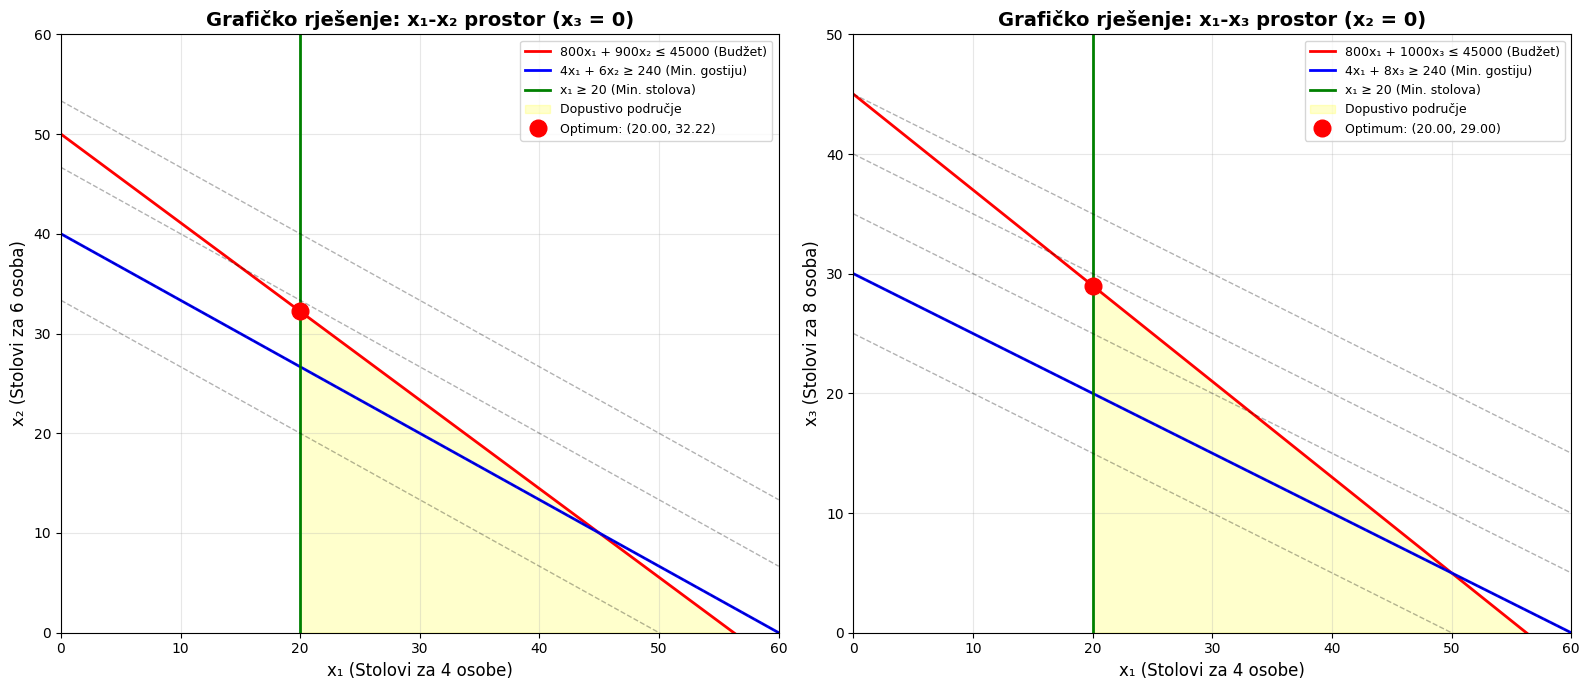

Grafikon spremljen kao 'graficko_rjesenje.png'


In [139]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# ===== PRVI GRAFIKON: x1-x2 prostor (x3 = 0) =====
x1_range = np.linspace(0, 60, 400)

# Ograničenja kada je x3 = 0
# 800*x1 + 900*x2 <= 45000
x2_budzet = (45000 - 800*x1_range) / 900

# 4*x1 + 6*x2 >= 240
x2_min_gostiju = (240 - 4*x1_range) / 6

# x1 >= 20 (vertikalna linija)
x1_min = 20

# Crtanje ograničenja
ax1.plot(x1_range, x2_budzet, 'r-', linewidth=2, label='800x₁ + 900x₂ ≤ 45000 (Budžet)')
ax1.plot(x1_range, x2_min_gostiju, 'b-', linewidth=2, label='4x₁ + 6x₂ ≥ 240 (Min. gostiju)')
ax1.axvline(x=x1_min, color='g', linewidth=2, linestyle='-', label='x₁ ≥ 20 (Min. stolova)')

# Područje dopustivosti
ax1.fill_between(x1_range, 0, x2_budzet, where=(x2_budzet >= 0) & (x1_range >= x1_min), 
                  alpha=0.2, color='yellow', label='Dopustivo područje')

# Izokvante funkcije cilja (4*x1 + 6*x2 = const)
for z_val in [200, 240, 280, 320]:
    x2_obj = (z_val - 4*x1_range) / 6
    ax1.plot(x1_range, x2_obj, 'k--', alpha=0.3, linewidth=1)

# Optimalno rješenje za x3=0
prob_2d = pulp.LpProblem("2D_x1_x2", pulp.LpMaximize)
x1_2d = pulp.LpVariable("x1", lowBound=0)
x2_2d = pulp.LpVariable("x2", lowBound=0)
prob_2d += 4*x1_2d + 6*x2_2d
prob_2d += 800*x1_2d + 900*x2_2d <= 45000
prob_2d += 4*x1_2d + 6*x2_2d >= 240
prob_2d += x1_2d >= 20
prob_2d.solve()

if x1_2d.varValue is not None and x2_2d.varValue is not None:
    ax1.plot(x1_2d.varValue, x2_2d.varValue, 'ro', markersize=12, 
             label=f'Optimum: ({x1_2d.varValue:.2f}, {x2_2d.varValue:.2f})', zorder=5)

ax1.set_xlabel('x₁ (Stolovi za 4 osobe)', fontsize=12)
ax1.set_ylabel('x₂ (Stolovi za 6 osoba)', fontsize=12)
ax1.set_title('Grafičko rješenje: x₁-x₂ prostor (x₃ = 0)', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(0, 60)
ax1.set_ylim(0, 60)

# ===== DRUGI GRAFIKON: x1-x3 prostor (x2 = 0) =====
x1_range2 = np.linspace(0, 60, 400)

# Ograničenja kada je x2 = 0
# 800*x1 + 1000*x3 <= 45000
x3_budzet = (45000 - 800*x1_range2) / 1000

# 4*x1 + 8*x3 >= 240
x3_min_gostiju = (240 - 4*x1_range2) / 8

# Crtanje ograničenja
ax2.plot(x1_range2, x3_budzet, 'r-', linewidth=2, label='800x₁ + 1000x₃ ≤ 45000 (Budžet)')
ax2.plot(x1_range2, x3_min_gostiju, 'b-', linewidth=2, label='4x₁ + 8x₃ ≥ 240 (Min. gostiju)')
ax2.axvline(x=x1_min, color='g', linewidth=2, linestyle='-', label='x₁ ≥ 20 (Min. stolova)')

# Područje dopustivosti
ax2.fill_between(x1_range2, 0, x3_budzet, where=(x3_budzet >= 0) & (x1_range2 >= x1_min), 
                  alpha=0.2, color='yellow', label='Dopustivo područje')

# Izokvante funkcije cilja (4*x1 + 8*x3 = const)
for z_val in [200, 240, 280, 320, 360]:
    x3_obj = (z_val - 4*x1_range2) / 8
    ax2.plot(x1_range2, x3_obj, 'k--', alpha=0.3, linewidth=1)

# Optimalno rješenje za x2=0
prob_2d_2 = pulp.LpProblem("2D_x1_x3", pulp.LpMaximize)
x1_2d_2 = pulp.LpVariable("x1", lowBound=0)
x3_2d_2 = pulp.LpVariable("x3", lowBound=0)
prob_2d_2 += 4*x1_2d_2 + 8*x3_2d_2
prob_2d_2 += 800*x1_2d_2 + 1000*x3_2d_2 <= 45000
prob_2d_2 += 4*x1_2d_2 + 8*x3_2d_2 >= 240
prob_2d_2 += x1_2d_2 >= 20
prob_2d_2.solve()

if x1_2d_2.varValue is not None and x3_2d_2.varValue is not None:
    ax2.plot(x1_2d_2.varValue, x3_2d_2.varValue, 'ro', markersize=12, 
             label=f'Optimum: ({x1_2d_2.varValue:.2f}, {x3_2d_2.varValue:.2f})', zorder=5)

ax2.set_xlabel('x₁ (Stolovi za 4 osobe)', fontsize=12)
ax2.set_ylabel('x₃ (Stolovi za 8 osoba)', fontsize=12)
ax2.set_title('Grafičko rješenje: x₁-x₃ prostor (x₂ = 0)', fontsize=14, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 50)

plt.tight_layout()
plt.savefig('graficko_rjesenje.png', dpi=150, bbox_inches='tight')
plt.show()

print("Grafikon spremljen kao 'graficko_rjesenje.png'")

## 8. Komentari i zaključci

### 8.1 Je li zadatak trebalo rješavati kao cjelobrojni problem?

**DA**, zadatak bi trebalo rješavati kao cjelobrojni problem jer:

1. **Priroda varijabli**: Broj stolova mora biti cijeli broj - ne možemo imati 20.5 stolova
2. **Praktična primjena**: U stvarnosti, restoran mora kupiti cijeli broj stolova
3. **Razlika u rješenjima**: Postoji razlika između kontinuiranog i cjelobrojnog rješenja

Međutim, ako kontinuirano rješenje daje cijele brojeve, tada nema potrebe za dodatnim cjelobrojnim rješavanjem jer je kontinuirano rješenje već optimalno i izvedivo.

### 8.2 Analiza dualnog problema

Dualni problem pokazuje:
- **Teorem dualizacije**: Optimalne vrijednosti primalne i dualne funkcije cilja su jednake
- **Dualne varijable (shadow prices)**: Pokazuju koliko bi se promijenila funkcija cilja ako promijenimo desnu stranu ograničenja za jednu jedinicu
- **Ekonomska interpretacija**: Dualne varijable predstavuju marginalnu vrijednost resursa

### 8.3 Iskorištenost resursa

Na temelju shadow prices možemo zaključiti:
- **Aktivna ograničenja** (shadow price ≠ 0): Resursi su potpuno iskorišteni i njihovo povećanje bi poboljšalo rješenje
- **Neaktivna ograničenja** (shadow price = 0): Resursi nisu potpuno iskorišteni i njihovo povećanje ne bi utjecalo na rješenje

### 8.4 Utjecaj dodatnih/smanjenih resursa

- **Budžet**: Ako je shadow price pozitivan, dodatna kuna budžeta povećala bi broj gostiju
- **Minimalni broj gostiju**: Ako je shadow price negativan, smanjenje ovog zahtjeva moglo bi poboljšati rješenje
- **Minimalni broj stolova za 4**: Ako je shadow price negativan, smanjenje ovog zahtjeva omogućilo bi bolju optimizaciju

### 8.5 Grafičko rješenje

Grafičko rješenje pokazuje:
- **Dopustivo područje**: Područje koje zadovoljava sva ograničenja
- **Optimalna točka**: Nalazi se na granici dopustivog područja (u vrhu)
- **Izokvante**: Linije konstantne vrijednosti funkcije cilja pokazuju smjer optimizacije

### 8.6 Završni sažetak

- **Optimalna nabava stolova**: 20 stolova za četvero (x₁), 0 stolova za šestero (x₂) i 29 stolova za osmero (x₃). Maksimalni kapacitet je 312 gostiju, čime se u potpunosti koristi budžet od 45 000 kn uz poštivanje svih ograničenja.
- **Interpretacija dualnih varijabli**: Povećanje budžeta ima pozitivnu sjenu cijenu (0,008), dok bi popuštanje zahtjeva za minimalnim brojem stolova za četvero donijelo dodatnu korist (sjena cijena 2,4).
